# 로지스틱 회귀 실습 — Social_Network_Ads

원본: 카페 Untitled3 (2).ipynb.

> **쉬운 말**
> 나이·연봉으로 "광고 보고 샀을까?"(0/1)를 맞춥니다.
> 모델은 **확률**을 내고, **임계값(threshold)** 으로 예/아니오를 가릅니다.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score, precision_score, recall_score
from sklearn.linear_model import LogisticRegression

# 권장: Jupyter 폴더 기준으로 ../data 에 CSV가 있을 때
# 없으면 아래 원본 절대 경로를 쓰세요. (C:/run/... 은 수업 환경 경로)
DATA_PATH = "../data/Social_Network_Ads.csv"
# DATA_PATH = "C:/run/Social_Network_Ads.csv"  # 원본 경로 백업

data = pd.read_csv(DATA_PATH)
data


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


## 로지스틱 회귀가 하는 일 (쉬운 말)

선형회귀처럼 y = wx + b로 숫자를 만든 뒤, **시그모이드(sigmoid)** 로 0~1 사이 확률로 바꿉니다.

- 확률 ≥ 임계값(기본 0.5) → 1(구매)
- 확률 < 임계값 → 0(미구매)

자세한 이론은 session15를 보세요. 아래는 실습입니다.


In [2]:
# 로지스틱 회귀: 선형식 y=wx+b 로 예측값을 만든 뒤
# 시그모이드로 0~1 확률로 바꾼다. (이진 분류)
# 기본 임계값 0.5: 이상이면 1, 미만이면 0


## 1. 타겟 분포 확인

Purchased가 0/1 몇 개인지 봅니다. 한쪽이 너무 많으면 점수 해석에 주의합니다.


In [3]:
# 샀다(1) / 안 샀다(0) 개수
data["Purchased"].value_counts()


Purchased
0    257
1    143
Name: count, dtype: int64

## 2. Feature / 라벨 만들기

학습에 쓸 칸만 남깁니다. User ID, Gender는 이번 실습에서 빼고, Age·EstimatedSalary만 씁니다.


In [4]:
# Feature: 나이, 연봉만 (Purchased / Gender / User ID 제외)
features = data.drop(columns=["Purchased", "Gender", "User ID"]).values
# float32 = 자리 수를 줄여 메모리를 아낌
label = data["Purchased"].values.astype("float32")
print(label)


[0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.
 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0.
 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 1. 0. 1. 0. 1. 1. 0. 0. 0. 1.
 0. 0. 0. 1. 0. 1. 1. 1. 0. 0. 1. 1. 0. 1. 1. 0. 1. 1. 0. 1. 0. 0. 0. 1.
 1. 0. 1. 1. 0. 1. 0. 1. 0. 1. 0. 0. 1. 1. 0. 1. 0. 0. 1. 1. 0. 1. 1. 0.
 1. 1. 0. 0. 1. 0. 0. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1. 0. 1. 1. 0. 1. 0. 1.
 0. 1. 1. 1. 1. 0. 0. 0. 1. 1. 0. 1. 1. 1. 1. 1. 0. 0. 0. 1. 1. 0. 0. 1.
 0. 1. 0. 1. 1. 0. 1. 0. 1. 1. 0. 1. 1. 0. 0. 0. 1.

## 3. 학습 / 테스트 나누기

test_size=0.2 → 80% 연습, 20% 시험.
random_state=1로 같은 분할을 재현합니다.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    features, label, test_size=0.2, random_state=1
)


## 4. 표준화 (StandardScaler) — 학습 표에만 fit

나이와 연봉은 단위가 다릅니다. 스케일을 맞춥니다.

> **쉬운 말**
> **fit** = 학습 표의 평균·표준편차를 기억. **transform** = 그 기억으로 변환.
> 테스트에는 fit을 다시 하지 않습니다 (시험지 답을 미리 보는 것과 같음).


In [6]:
# 정규화(표준화): 학습에만 fit, 테스트는 transform만
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)


In [7]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape


((320, 2), (80, 2), (320,), (80,))

## 5. 로지스틱 회귀 학습

solver="lbfgs" = 가중치를 맞추는 최적화 방법입니다.


In [8]:
lr = LogisticRegression(solver="lbfgs", random_state=1)
lr.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

## 6. 기본 예측과 점수

predict는 기본 임계값 0.5로 0/1을 냅니다.


In [9]:
y_pred = lr.predict(X_test)
y_pred


array([0., 0., 1., 1., 0., 0., 0., 1., 0., 1., 0., 0., 0., 1., 1., 1., 1.,
       0., 0., 1., 0., 1., 1., 1., 0., 0., 1., 1., 1., 1., 0., 0., 0., 1.,
       0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 1., 0., 0., 1., 0., 1., 0.,
       0., 1., 0., 1., 0., 1., 0., 1., 1., 0., 0., 1., 0., 0., 1., 0., 0.,
       1., 0., 1., 0., 1., 0., 0., 1., 0., 0., 0., 0.], dtype=float32)

In [10]:
# 정확도(accuracy): 전체 중 맞힌 비율
accuracy_score(y_test, y_pred)


0.8375

In [11]:
# 정밀도(precision): "산다"고 한 것 중 진짜 산 비율
precision_score(y_test, y_pred)


0.7878787878787878

## 7. 확률 보기 — predict_proba

각 샘플마다 [안 살 확률, 살 확률]이 나옵니다. 두 번째 칸([:, 1])이 구매 확률입니다.


In [12]:
y_proba = lr.predict_proba(X_test)
y_proba


array([[9.45811200e-01, 5.41887996e-02],
       [7.45476502e-01, 2.54523498e-01],
       [3.81696656e-01, 6.18303344e-01],
       [2.10205055e-01, 7.89794945e-01],
       [8.57890696e-01, 1.42109304e-01],
       [7.58667300e-01, 2.41332700e-01],
       [9.98324542e-01, 1.67545836e-03],
       [9.05884469e-02, 9.09411553e-01],
       [9.89943575e-01, 1.00564250e-02],
       [1.59390228e-02, 9.84060977e-01],
       [8.55976082e-01, 1.44023918e-01],
       [6.46303438e-01, 3.53696562e-01],
       [8.25525238e-01, 1.74474762e-01],
       [2.34363834e-02, 9.76563617e-01],
       [5.00518828e-02, 9.49948117e-01],
       [3.56659756e-03, 9.96433402e-01],
       [1.01625917e-02, 9.89837408e-01],
       [9.80713225e-01, 1.92867754e-02],
       [9.28285879e-01, 7.17141213e-02],
       [4.84069275e-03, 9.95159307e-01],
       [5.73506701e-01, 4.26493299e-01],
       [7.61969369e-02, 9.23803063e-01],
       [4.17987748e-02, 9.58201225e-01],
       [4.89537772e-01, 5.10462228e-01],
       [7.469811

In [13]:
# 클래스 1(구매) 확률만 선택
y_proba1 = y_proba[:, 1]
y_proba1


array([5.41887996e-02, 2.54523498e-01, 6.18303344e-01, 7.89794945e-01,
       1.42109304e-01, 2.41332700e-01, 1.67545836e-03, 9.09411553e-01,
       1.00564250e-02, 9.84060977e-01, 1.44023918e-01, 3.53696562e-01,
       1.74474762e-01, 9.76563617e-01, 9.49948117e-01, 9.96433402e-01,
       9.89837408e-01, 1.92867754e-02, 7.17141213e-02, 9.95159307e-01,
       4.26493299e-01, 9.23803063e-01, 9.58201225e-01, 5.10462228e-01,
       2.53018850e-01, 2.87878796e-03, 9.37460626e-01, 8.47705891e-01,
       7.41953045e-01, 9.81538960e-01, 1.39236214e-01, 6.39803414e-03,
       7.53822340e-03, 9.71829545e-01, 5.18270081e-02, 8.47243281e-02,
       1.30317706e-03, 1.56055434e-01, 4.55527902e-01, 8.66225280e-04,
       9.82239257e-01, 9.92080543e-01, 4.77105064e-01, 1.07035359e-02,
       9.40612597e-01, 3.41242166e-01, 4.88837988e-01, 9.42352137e-01,
       4.09283199e-01, 7.28176000e-01, 9.82520570e-03, 1.36436174e-01,
       5.88182576e-01, 3.15200060e-01, 5.20298891e-01, 1.83717633e-01,
      

In [14]:
# 기본 임계값 0.5 초과인 샘플 개수
sum(y_proba1 > 0.5)


np.int64(33)

## 8. 임계값(threshold) 바꾸기

임계값을 낮추면 "산다"고 더 자주 말합니다 → 보통 **재현율↑, 정밀도↓**.  
임계값을 높이면 반대로 **정밀도↑, 재현율↓** 인 경우가 많습니다.

- **정밀도(precision)**: 산다고 한 것 중 진짜 산 비율
- **재현율(recall)**: 진짜 산 사람 중 모델이 찾아낸 비율
- **F1**: 정밀도와 재현율의 조화평균


In [15]:
y_proba1 = y_proba[:, 1]

threshold = 0.3
# 0.3보다 크면 True(1), 작으면 False(0)
y_pred1 = y_proba1 > threshold

print(sum(y_pred1))  # 1로 분류된 개수
print(precision_score(y_test, y_pred1))  # 정밀도
print(recall_score(y_test, y_pred1))  # 재현율
print(f1_score(y_test, y_pred1))  # F1

print("=================================================")

threshold = 0.6
y_pred2 = y_proba1 > threshold
print(sum(y_pred2))
print(precision_score(y_test, y_pred2))
print(recall_score(y_test, y_pred2))
print(f1_score(y_test, y_pred2))


44
0.7045454545454546
0.96875
0.8157894736842105
30
0.8
0.75
0.7741935483870968


## 9. 혼동행렬 (Confusion Matrix)

labels=[1, 0]이면 행·열 순서가 positive(1), negative(0)입니다.

```
[TP  FN]
[FP  TN]
```


In [16]:
# labels -> 행·열 순서: positive(1), negative(0)
con = confusion_matrix(y_test, y_pred, labels=[1, 0])
# [TP] [FN]
# [FP] [TN]
con


array([[26,  6],
       [ 7, 41]])

c:\Users\dmsrh\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\dmsrh\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\dmsrh\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\dmsrh\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


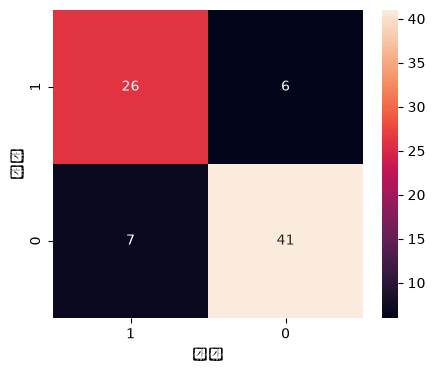

In [17]:
plt.figure(figsize=(5, 4))
sns.heatmap(con, annot=True, xticklabels=[1, 0], yticklabels=[1, 0])
plt.xlabel("예측")
plt.ylabel("실제")
plt.show()
